# Week 7 Take Home

This week has two parts. Complete **both**.

| Part | Lessons | Project |
|------|---------|---------|
| **A. Cleaning & Visualising Data** | `1-Cleaning & Visualising Data/` | Holiday weather |
| **B. Transforming & Combining Data** | `2-Transforming & Combining Data/` | GDP and life expectancy + your own World Bank project |

Data for both parts comes from the cohort database (schemas `week07` and `week08`). See `Data Access (SQL).md`.

---
# Part A: Cleaning & Visualising Data

In [19]:
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

import warnings
warnings.simplefilter('ignore', FutureWarning)

import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
from scipy.stats import spearmanr


In [ ]:
GDP_INDICATOR  = "NY.GDP.MKTP.CD"
LIFE_INDICATOR = "SP.DYN.LE00.IN"
POP_INDICATOR  = "SP.POP.TOTL"

### Solve `1-Cleaning & Visualising Data/1.ipynb` Tasks Below

In [84]:
london = run_query("SELECT * FROM week07.london_2014")

london.columns = london.columns.str.strip()

london = london.rename(
    columns={'WindDirDegrees<br />': 'WindDirDegrees'}
)
london['WindDirDegrees'] = (
    london['WindDirDegrees']
    .astype(str)
    .str.replace('<br />', '', regex=False)
    .astype('int64')
)

london['GMT'] = pd.to_datetime(london['GMT'])

print('Days with no recorded event:', london['Events'].isnull().sum())
london['Events'] = london['Events'].fillna('')
print('Days with no recorded event after filling:', london['Events'].isnull().sum())

london.dtypes

Days with no recorded event: 114
Days with no recorded event after filling: 0


GMT                           datetime64[us]
Max TemperatureC                       int64
Mean TemperatureC                      int64
Min TemperatureC                       int64
Dew PointC                             int64
MeanDew PointC                         int64
Min DewpointC                          int64
Max Humidity                           int64
Mean Humidity                          int64
Min Humidity                           int64
Max Sea Level PressurehPa              int64
Mean Sea Level PressurehPa             int64
Min Sea Level PressurehPa              int64
Max VisibilityKm                       int64
Mean VisibilityKm                      int64
Min VisibilitykM                       int64
Max Wind SpeedKm/h                     int64
Mean Wind SpeedKm/h                    int64
Max Gust SpeedKm/h                   float64
Precipitationmm                      float64
CloudCover                           float64
Events                                   str
WindDirDeg

In [ ]:
london.columns.tolist()


['GMT',
 'Max TemperatureC',
 'Mean TemperatureC',
 'Min TemperatureC',
 'Dew PointC',
 'MeanDew PointC',
 'Min DewpointC',
 'Max Humidity',
 'Mean Humidity',
 'Min Humidity',
 'Max Sea Level PressurehPa',
 'Mean Sea Level PressurehPa',
 'Min Sea Level PressurehPa',
 'Max VisibilityKm',
 'Mean VisibilityKm',
 'Min VisibilitykM',
 'Max Wind SpeedKm/h',
 'Mean Wind SpeedKm/h',
 'Max Gust SpeedKm/h',
 'Precipitationmm',
 'CloudCover',
 'Events',
 'WindDirDegrees']

In [21]:
london.shape

(365, 23)

In [ ]:
northerly = london[
    (london['WindDirDegrees'] >= 350) |
    (london['WindDirDegrees'] <= 10)
]

northerly


,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
84,2014-03-26,9,6,2,4,2,-1,100,80,39,...,27,10,1,26,10,NaN,2.03,4.0,Fog-Rain,3
90,2014-04-01,19,13,7,11,9,6,100,80,39,...,19,7,0,16,5,NaN,0.00,4.0,Fog-Rain,6
100,2014-04-11,16,12,9,5,4,2,71,53,28,...,31,18,10,13,8,NaN,0.00,1.0,,351
110,2014-04-21,19,12,5,11,8,4,100,78,31,...,26,7,0,14,6,NaN,9.91,3.0,Fog-Rain-Thunderstorm,356
174,2014-06-24,24,19,13,15,12,9,94,66,27,...,31,12,0,23,8,37.0,0.00,3.0,Fog,350
179,2014-06-29,19,16,12,11,9,5,88,65,31,...,31,16,10,19,10,NaN,0.00,2.0,Rain,9
190,2014-07-10,22,18,14,13,11,9,82,64,44,...,31,19,10,16,14,NaN,0.00,3.0,,1
208,2014-07-28,23,19,14,16,12,9,94,66,33,...,26,12,2,21,10,NaN,17.02,2.0,Rain-Thunderstorm,3
249,2014-09-07,21,17,13,14,12,8,94,71,41,...,23,10,2,11,6,NaN,0.00,4.0,,354
250,2014-09-08,22,16,10,13,9,7,94,64,28,...,27,12,5,11,6,NaN,0.00,1.0,,351


In [ ]:
dates = london['GMT']

london[
    (dates >= datetime(2014, 4, 1)) &
    (dates <= datetime(2014, 4, 11))
]


,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
90,2014-04-01,19,13,7,11,9,6,100,80,39,...,19,7,0,16,5,NaN,0.00,4.0,Fog-Rain,6
91,2014-04-02,18,14,11,11,9,7,88,71,48,...,10,8,5,23,13,NaN,0.00,1.0,Rain,85
92,2014-04-03,18,14,11,11,9,9,88,75,52,...,21,7,3,26,11,NaN,0.00,5.0,,96
93,2014-04-04,15,12,9,10,8,6,88,71,46,...,31,11,2,24,14,NaN,0.00,5.0,,253
94,2014-04-05,14,10,6,11,8,5,100,83,56,...,31,12,1,26,13,50.0,0.00,5.0,Fog-Rain,197
95,2014-04-06,16,14,12,12,12,11,94,88,67,...,31,12,5,35,21,48.0,2.03,6.0,Rain,213
96,2014-04-07,14,11,8,12,11,6,94,87,76,...,31,14,5,29,23,42.0,2.03,5.0,Rain,209
97,2014-04-08,14,9,5,6,3,-1,87,64,26,...,31,15,10,39,23,NaN,0.00,2.0,Rain,269
98,2014-04-09,17,10,4,7,6,3,93,68,38,...,31,14,6,23,13,NaN,0.00,2.0,,261
99,2014-04-10,16,11,6,6,5,3,93,62,31,...,31,14,9,19,10,NaN,0.00,3.0,,278


In [24]:
missing_gust = london[london['Max Gust SpeedKm/h'].isnull()]
missing_gust.head()


,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
4,2014-01-05,12,7,1,11,4,-1,100,88,77,...,31,14,5,35,16,NaN,0.25,5.0,Rain,199
10,2014-01-11,9,4,0,7,3,-1,100,80,51,...,31,12,6,24,14,NaN,0.00,4.0,Rain,259
11,2014-01-12,10,4,-2,9,3,-2,100,91,79,...,31,9,1,32,10,NaN,0.51,6.0,Fog-Rain,126
12,2014-01-13,9,7,5,8,4,3,93,85,71,...,31,16,5,34,19,NaN,5.08,2.0,Rain,205
13,2014-01-14,7,4,1,5,2,0,100,82,55,...,31,15,10,21,13,NaN,0.25,3.0,Rain,242


### Solve `1-Cleaning & Visualising Data/2.ipynb` Tasks Below

<Axes: >

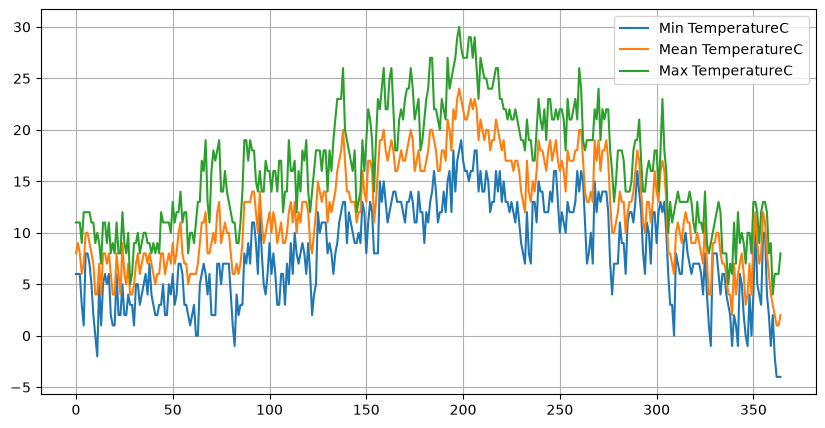

In [25]:
%matplotlib inline
london[['Min TemperatureC', 'Mean TemperatureC', 'Max TemperatureC']].plot(grid=True, figsize=(10, 5))

In [26]:
london.index = london['GMT']
london = london.sort_index()
london.loc[datetime(2014, 12, 8):datetime(2014, 12, 12)]

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
GMT,,,,,,,,,,,,,,,,,,,,,
2014-12-08,2014-12-08,7,4,1,2,1,-1,93,76,51,...,31,17,10,23,13,NaN,0.00,2.0,Rain,270
2014-12-09,2014-12-09,12,6,-1,11,3,-1,100,86,64,...,31,15,3,37,14,52.0,0.25,5.0,Rain,224
2014-12-10,2014-12-10,9,7,6,11,3,1,90,70,44,...,31,18,3,40,27,NaN,0.00,2.0,Rain,246
2014-12-11,2014-12-11,10,8,5,6,3,2,82,72,51,...,31,15,10,40,31,NaN,0.25,2.0,Rain,246
2014-12-12,2014-12-12,9,6,2,9,4,-1,94,79,59,...,31,11,3,40,26,55.0,1.02,3.0,Rain,253


<Axes: xlabel='GMT'>

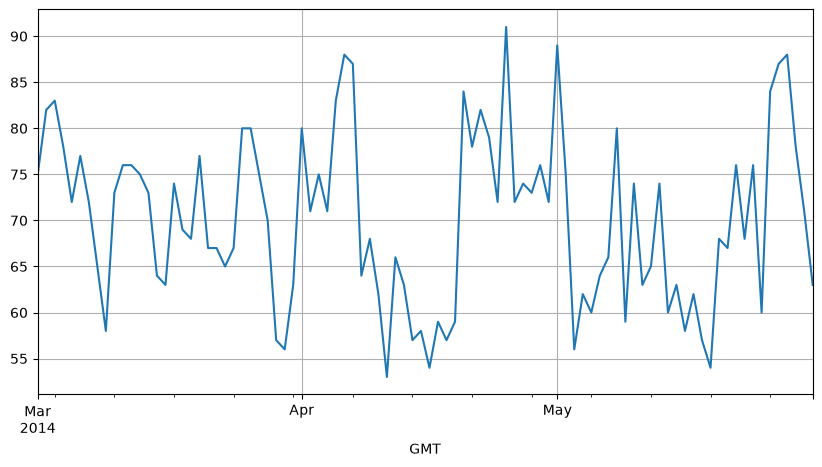

In [28]:
london.loc[
    datetime(2014, 3, 1):datetime(2014, 5, 31),
    'Mean Humidity'
].plot(grid=True, figsize=(10, 5))

## Project A: Holiday weather


There is nothing I like better than taking a holiday. In this project I am going to use the historic weather data from the Weather Underground for London to try to predict two good weather weeks to take off as holiday. Of course the weather in the summer of 2025 may be very different to 2020 but it should give some indication of when would be a good time to take a summer break.

## Getting the data

Weather Underground keeps historical weather data collected in many airports around the world. Right-click on the following URL and choose 'Open Link in New Window' (or similar, depending on your browser):

http://www.wunderground.com/history

When the new page opens start typing 'LHR' in the 'Location' input box and when the pop up menu comes up with the option 'LHR, United Kingdom' select it and then click on 'Submit'. 

When the next page opens with London Heathrow data, click on the 'Custom' tab and select the time period From: 1 January 2023 to: 31 December 2023 and then click on 'Get History'. The data for that year should then be displayed further down the page. 

You can copy each month's data directly from the browser to a text editor like Notepad or TextEdit, to obtain a single file with as many months as you wish.


Now load the CSV file into a dataframe making sure that any extra spaces are skipped:

### Step-1 Cleaning the data


In [91]:
london23 = pd.read_csv(
    "london_2023_wunderground.csv",
    skipinitialspace=True,
    parse_dates=["Date"]
).set_index("Date")

london23["Precipitationmm"] = london23["Precipitation_WU_mm"]

london23.info()
london23.describe()

<class 'pandas.DataFrame'>
DatetimeIndex: 365 entries, 2023-01-01 to 2023-12-31
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Max TemperatureC            365 non-null    int64  
 1   Mean TemperatureC           365 non-null    float64
 2   Min TemperatureC            365 non-null    int64  
 3   Dew PointC                  365 non-null    int64  
 4   MeanDew PointC              365 non-null    float64
 5   Min DewpointC               365 non-null    int64  
 6   Max Humidity                365 non-null    int64  
 7   Mean Humidity               365 non-null    float64
 8   Min Humidity                365 non-null    int64  
 9   Max Wind SpeedKm/h          365 non-null    int64  
 10  Mean Wind SpeedKm/h         365 non-null    float64
 11  Min Wind SpeedKm/h          365 non-null    int64  
 12  Max Sea Level PressurehPa   365 non-null    float64
 13  Mean Sea Level PressurehPa 

,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Min Wind SpeedKm/h,Max Sea Level PressurehPa,Mean Sea Level PressurehPa,Min Sea Level PressurehPa,Precipitation_WU_mm,Precipitationmm
count,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.0,365.0
mean,16.005479,12.317808,8.731507,10.161644,7.893973,5.484932,92.561644,76.371507,58.172603,24.427397,14.973425,6.528767,1014.192329,1010.830137,1007.423836,0.0,0.0
std,6.374742,5.564658,5.285707,4.628348,4.636663,4.815031,6.316267,9.635438,14.086870,8.488733,6.279579,4.588851,11.082458,12.013594,13.203979,0.0,0.0
min,0.000000,-2.300000,-7.000000,-2.000000,-4.000000,-8.000000,69.000000,49.400000,24.000000,7.000000,2.700000,0.000000,974.100000,963.700000,952.200000,0.0,0.0
25%,11.000000,8.200000,5.000000,7.000000,5.100000,3.000000,88.000000,70.000000,47.000000,19.000000,10.200000,4.000000,1008.000000,1003.600000,1000.000000,0.0,0.0
50%,15.000000,11.800000,9.000000,10.000000,8.000000,6.000000,94.000000,77.000000,57.000000,22.000000,13.900000,6.000000,1015.000000,1011.900000,1009.000000,0.0,0.0
75%,21.000000,16.900000,13.000000,14.000000,11.700000,9.000000,100.000000,83.600000,70.000000,30.000000,18.800000,9.000000,1022.000000,1018.400000,1016.000000,0.0,0.0
max,32.000000,27.200000,23.000000,20.000000,17.200000,16.000000,100.000000,95.800000,93.000000,52.000000,37.100000,26.000000,1043.900000,1041.300000,1036.900000,0.0,0.0


In [32]:
london23["Precipitationmm"] = london23["Precipitation_WU_mm"]

In [36]:
print("Rows and columns:", london23.shape)

print("\nColumn names:")
print(london23.columns.tolist())

print("\nDate range:")
print(london23.index.min(), "to", london23.index.max())

print("\nMissing values per column:")
print(london23.isnull().sum())

print("\nDuplicate dates:", london23.index.duplicated().sum())

Rows and columns: (365, 17)

Column names:
['Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC', 'Dew PointC', 'MeanDew PointC', 'Min DewpointC', 'Max Humidity', 'Mean Humidity', 'Min Humidity', 'Max Wind SpeedKm/h', 'Mean Wind SpeedKm/h', 'Min Wind SpeedKm/h', 'Max Sea Level PressurehPa', 'Mean Sea Level PressurehPa', 'Min Sea Level PressurehPa', 'Precipitation_WU_mm', 'Precipitationmm']

Date range:
2023-01-01 00:00:00 to 2023-12-31 00:00:00

Missing values per column:
Max TemperatureC              0
Mean TemperatureC             0
Min TemperatureC              0
Dew PointC                    0
MeanDew PointC                0
Min DewpointC                 0
Max Humidity                  0
Mean Humidity                 0
Min Humidity                  0
Max Wind SpeedKm/h            0
Mean Wind SpeedKm/h           0
Min Wind SpeedKm/h            0
Max Sea Level PressurehPa     0
Mean Sea Level PressurehPa    0
Min Sea Level PressurehPa     0
Precipitation_WU_mm           0
Prec

### Step-2 Finding a summer break

According to meteorologists, summer extends for the whole months of June, July, and August in the northern hemisphere and the whole months of December, January, and February in the southern hemisphere. So create a dataframe that holds just those months using the `datetime` index.

In [38]:
print("Weather Underground column:")
print(london23["Precipitation_WU_mm"].describe())

print("\nOther precipitation column:")
print(london23["Precipitationmm"].describe())

print("\nAre all values identical?")
print(
    london23["Precipitation_WU_mm"].equals(
        london23["Precipitationmm"]
    )
)

print("\nDistinct values in each column:")
print("WU:", london23["Precipitation_WU_mm"].nunique(dropna=False))
print("Other:", london23["Precipitationmm"].nunique(dropna=False))

Weather Underground column:
count    365.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: Precipitation_WU_mm, dtype: float64

Other precipitation column:
count    365.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: Precipitationmm, dtype: float64

Are all values identical?
True

Distinct values in each column:
WU: 1
Other: 1


In [40]:
summer23 = london23[london23.index.month.isin([6, 7, 8])]

print("Summer rows and columns:", summer23.shape)

print("\nSummer temperature summary:")
print(
    summer23[
        ["Max TemperatureC", "Mean TemperatureC", "Min TemperatureC"]
    ].describe()
)

print("\nSummer date range:")
print(summer23.index.min(), "to", summer23.index.max())

Summer rows and columns: (92, 17)

Summer temperature summary:
       Max TemperatureC  Mean TemperatureC  Min TemperatureC
count         92.000000          92.000000         92.000000
mean          22.673913          18.147826         13.967391
std            3.145234           2.276467          2.269972
min           17.000000          13.300000          8.000000
25%           20.750000          16.500000         12.000000
50%           22.000000          18.300000         14.000000
75%           24.250000          19.900000         16.000000
max           31.000000          23.200000         19.000000

Summer date range:
2023-06-01 00:00:00 to 2023-08-31 00:00:00


In [ ]:
def best_weeks(summer):
    weeks = pd.DataFrame({
        "avg_max_temp": summer["Max TemperatureC"].rolling(7).mean(),
        "total_rain_mm": summer["Precipitation_WU_mm"].rolling(7).sum(),
    }).dropna()

    weeks[["avg_max_temp", "total_rain_mm"]] = weeks[["avg_max_temp", "total_rain_mm"]].round(2)

    weeks["start"] = weeks.index - pd.Timedelta(days=6)
    weeks["end"] = weeks.index

    dry = weeks[
        weeks["total_rain_mm"]
        <= weeks["total_rain_mm"].quantile(0.25)
    ]

    best = dry.sort_values(["avg_max_temp", "start"], ascending=[False, True])

    first = best.iloc[0]
    second_candidates = best[
        (best["start"] > first["end"])
        | (best["end"] < first["start"])
    ]

    if second_candidates.empty:
        raise ValueError("Could not find a second non-overlapping week.")

    second = second_candidates.iloc[0]

    chosen = pd.DataFrame([first, second])[
        ["start", "avg_max_temp", "total_rain_mm", "end"]
    ]

    return chosen.reset_index(drop=True)


summer23 = london23[london23.index.month.isin([6, 7, 8])]
chosen23 = best_weeks(summer23)
chosen23

,start,avg_max_temp,total_rain_mm,end
0,2023-06-09,28.00,0.0,2023-06-15
1,2023-06-19,26.43,0.0,2023-06-25


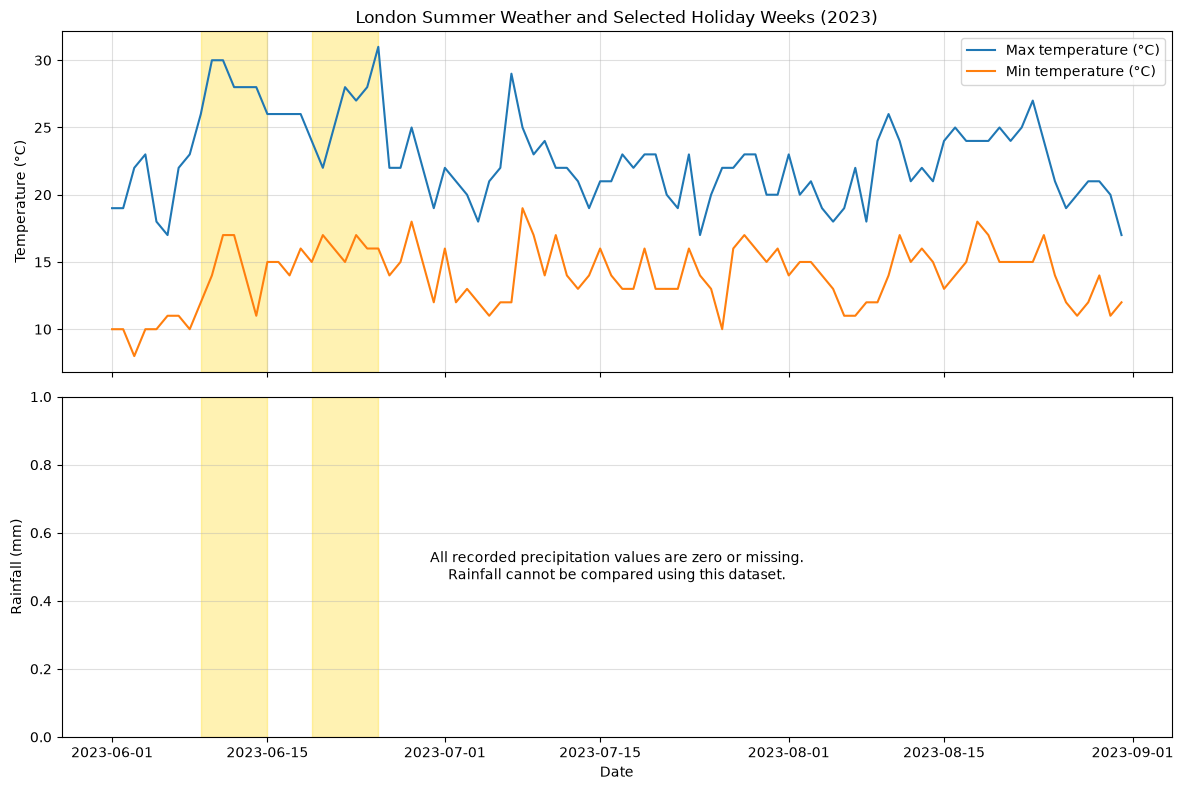

In [97]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

ax1.plot(
    summer23.index,
    summer23['Max TemperatureC'],
    label='Max temperature (°C)'
)
ax1.plot(
    summer23.index,
    summer23['Min TemperatureC'],
    label='Min temperature (°C)'
)

ax1.set_title('London Summer Weather and Selected Holiday Weeks (2023)')
ax1.set_ylabel('Temperature (°C)')
ax1.legend()
ax1.grid(True, alpha=0.4)

rain = summer23['Precipitationmm']

if rain.notna().any() and rain.max() > 0:
    ax2.bar(summer23.index, rain, color='steelblue')
    ax2.set_ylabel('Rainfall (mm)')
else:
    ax2.text(
        0.5, 0.5,
        'All recorded precipitation values are zero or missing.\n'
        'Rainfall cannot be compared using this dataset.',
        ha='center',
        va='center',
        transform=ax2.transAxes,
        wrap=True
    )
    ax2.set_ylabel('Rainfall (mm)')
    ax2.set_ylim(0, 1)

ax2.set_xlabel('Date')
ax2.grid(True, axis='y', alpha=0.4)

for _, row in chosen23.iterrows():
    ax1.axvspan(row['start'], row['end'], alpha=0.3, color='gold')
    ax2.axvspan(row['start'], row['end'], alpha=0.3, color='gold')

plt.tight_layout()
plt.show()

Conclusion

Based on London's 2023 Weather Underground data, the two selected summer holiday weeks were 9–15 June 2023 and 19–25 June 2023. The first week had an average maximum temperature of 28.00°C and a total recorded rainfall of 0.00 mm. The second week had an average maximum temperature of 26.43°C and a total recorded rainfall of 0.00 mm. The week of 10–16 June tied with the first on average maximum temperature, and the earlier week was chosen. Both selected weeks are well above the summer average maximum of about 22.7°C, so they appear to be promising options based on the recorded temperatures. However, all precipitation readings in the dataset were zero, so the weeks were chosen on temperature alone and rainfall could not distinguish between them. Rainfall data from another source would be needed to confirm that they are also dry. The analysis also uses only one year of data, and both weeks fall in June, so the results may not reliably predict conditions in another summer.

---
# Part B: Transforming & Combining Data

### Provide `2-Transforming & Combining Data/1.ipynb` Tasks Solutions below (Execute them)

In [53]:
table = [['UK', 2678454886796.7], ['USA', 16768100000000.0], ['China', 9240270452047.0],
         ['Brazil', 2245673032353.8], ['South Africa', 366057913367.1]]
gdp = pd.DataFrame(columns=['Country', 'GDP (US$)'], data=table)

table = [['China', 75], ['Russia', 71], ['United States', 79], ['India', 66], ['United Kingdom', 81]]
life = pd.DataFrame(columns=['Country name', 'Life expectancy (years)'], data=table)

def roundToMillions(value):
    return round(value / 1000000)

def usdToGBP(usd):
    return usd / 1.564768   # average rate during 2013

def expandCountry(name):
    if name == 'UK':
        name = 'United Kingdom'
    if name == 'USA':
        name = 'United States'
    return name

gdp['Country name'] = gdp['Country'].apply(expandCountry)
gdp['GDP (£m)'] = gdp['GDP (US$)'].apply(usdToGBP).apply(roundToMillions)
gdp = gdp[['Country name', 'GDP (£m)']]

gdpVsLife = pd.merge(gdp, life, on='Country name', how='inner')
gdpVsLife

,Country name,GDP (£m),Life expectancy (years)
0,United Kingdom,1711727,81
1,United States,10716029,79
2,China,5905202,75


In [54]:
table = [['China', 1357], ['India', 1279], ['United States', 316], ['Brazil', 200], ['Nigeria', 174]]
population = pd.DataFrame(columns=['Country name', 'Population (millions)'], data=table)
population

,Country name,Population (millions)
0,China,1357
1,India,1279
2,United States,316
3,Brazil,200
4,Nigeria,174


In [55]:
for how in ['left', 'right', 'outer', 'inner']:
    print(how.upper(), 'JOIN')
    display(pd.merge(gdpVsLife, population, on='Country name', how=how))

LEFT JOIN


,Country name,GDP (£m),Life expectancy (years),Population (millions)
0,United Kingdom,1711727,81,NaN
1,United States,10716029,79,316.0
2,China,5905202,75,1357.0


RIGHT JOIN


,Country name,GDP (£m),Life expectancy (years),Population (millions)
0,China,5905202.0,75.0,1357
1,India,NaN,NaN,1279
2,United States,10716029.0,79.0,316
3,Brazil,NaN,NaN,200
4,Nigeria,NaN,NaN,174


OUTER JOIN


,Country name,GDP (£m),Life expectancy (years),Population (millions)
0,Brazil,NaN,NaN,200.0
1,China,5905202.0,75.0,1357.0
2,India,NaN,NaN,1279.0
3,Nigeria,NaN,NaN,174.0
4,United Kingdom,1711727.0,81.0,NaN
5,United States,10716029.0,79.0,316.0


INNER JOIN


,Country name,GDP (£m),Life expectancy (years),Population (millions)
0,United States,10716029,79,316
1,China,5905202,75,1357


**Differences between the four joins**

- The left join keeps every country in gdpVsLife (United Kingdom, United States and China). The United Kingdom is missing from the population table, so its population is NaN.
- The right join keeps every country in the population table (China, India, United States, Brazil and Nigeria). India, Brazil and Nigeria are missing from gdpVsLife, so their GDP and life expectancy are NaN.
- The outer join keeps all six countries that appear in either table, with NaN wherever a table has no information about that country.
- The inner join keeps only the two countries found in both tables, the United States and China. It has no missing values.

In [ ]:
COUNTRY_SHORT = 'Country'
COUNTRY = 'Country name'
GDP_USD = 'GDP (US$)'
GDP_GBP = 'GDP (£m)'
LIFE = 'Life expectancy (years)'
POP = 'Population (millions)'

gdp = pd.DataFrame(columns=[COUNTRY_SHORT, GDP_USD], data=[
    ['UK', 2678454886796.7], ['USA', 16768100000000.0], ['China', 9240270452047.0],
    ['Brazil', 2245673032353.8], ['South Africa', 366057913367.1]])
life = pd.DataFrame(columns=[COUNTRY, LIFE], data=[
    ['China', 75], ['Russia', 71], ['United States', 79], ['India', 66], ['United Kingdom', 81]])
population = pd.DataFrame(columns=[COUNTRY, POP], data=[
    ['China', 1357], ['India', 1279], ['United States', 316], ['Brazil', 200], ['Nigeria', 174]])

gdp[COUNTRY] = gdp[COUNTRY_SHORT].apply(expandCountry)
gdp[GDP_GBP] = gdp[GDP_USD].apply(usdToGBP).apply(roundToMillions)
gdp = gdp[[COUNTRY, GDP_GBP]]

gdpVsLife = pd.merge(gdp, life, on=COUNTRY, how='inner')

for how in ['left', 'right', 'outer', 'inner']:
    display(pd.merge(gdpVsLife, population, on=COUNTRY, how=how))

,Country name,GDP (£m),Life expectancy (years),Population (millions)
0,United Kingdom,1711727,81,NaN
1,United States,10716029,79,316.0
2,China,5905202,75,1357.0


,Country name,GDP (£m),Life expectancy (years),Population (millions)
0,China,5905202.0,75.0,1357
1,India,NaN,NaN,1279
2,United States,10716029.0,79.0,316
3,Brazil,NaN,NaN,200
4,Nigeria,NaN,NaN,174


,Country name,GDP (£m),Life expectancy (years),Population (millions)
0,Brazil,NaN,NaN,200.0
1,China,5905202.0,75.0,1357.0
2,India,NaN,NaN,1279.0
3,Nigeria,NaN,NaN,174.0
4,United Kingdom,1711727.0,81.0,NaN
5,United States,10716029.0,79.0,316.0


,Country name,GDP (£m),Life expectancy (years),Population (millions)
0,United States,10716029,79,316
1,China,5905202,75,1357


In [103]:
COUNTRY_SHORT = 'Country'
COUNTRY_NAME = 'Country name'
GDP_USD = 'GDP (US$)'
GDP_GBP = 'GDP (£m)'
LIFE_YEARS = 'Life expectancy (years)'
POP_MILLIONS = 'Population (millions)'

gdp = pd.DataFrame(columns=[COUNTRY_SHORT, GDP_USD], data=[
    ['UK', 2678454886796.7], ['USA', 16768100000000.0], ['China', 9240270452047.0],
    ['Brazil', 2245673032353.8], ['South Africa', 366057913367.1]])
life = pd.DataFrame(columns=[COUNTRY_NAME, LIFE_YEARS], data=[
    ['China', 75], ['Russia', 71], ['United States', 79], ['India', 66], ['United Kingdom', 81]])
population = pd.DataFrame(columns=[COUNTRY_NAME, POP_MILLIONS], data=[
    ['China', 1357], ['India', 1279], ['United States', 316], ['Brazil', 200], ['Nigeria', 174]])

gdp[COUNTRY_NAME] = gdp[COUNTRY_SHORT].apply(expandCountry)
gdp[GDP_GBP] = gdp[GDP_USD].apply(usdToGBP).apply(roundToMillions)
gdp = gdp[[COUNTRY_NAME, GDP_GBP]]

gdpVsLife = pd.merge(gdp, life, on=COUNTRY_NAME, how='inner')

for how in ['left', 'right', 'outer', 'inner']:
    print(how.upper(), 'JOIN')
    display(pd.merge(gdpVsLife, population, on=COUNTRY_NAME, how=how))

LEFT JOIN


,Country name,GDP (£m),Life expectancy (years),Population (millions)
0,United Kingdom,1711727,81,NaN
1,United States,10716029,79,316.0
2,China,5905202,75,1357.0


RIGHT JOIN


,Country name,GDP (£m),Life expectancy (years),Population (millions)
0,China,5905202.0,75.0,1357
1,India,NaN,NaN,1279
2,United States,10716029.0,79.0,316
3,Brazil,NaN,NaN,200
4,Nigeria,NaN,NaN,174


OUTER JOIN


,Country name,GDP (£m),Life expectancy (years),Population (millions)
0,Brazil,NaN,NaN,200.0
1,China,5905202.0,75.0,1357.0
2,India,NaN,NaN,1279.0
3,Nigeria,NaN,NaN,174.0
4,United Kingdom,1711727.0,81.0,NaN
5,United States,10716029.0,79.0,316.0


INNER JOIN


,Country name,GDP (£m),Life expectancy (years),Population (millions)
0,United States,10716029,79,316
1,China,5905202,75,1357


### Provide `2-Transforming & Combining Data/2.ipynb` Tasks Solutions below (Execute them)

In [59]:
import time

def run_query_retry(sql, tries=5, wait=20):
    for attempt in range(1, tries + 1):
        try:
            return run_query(sql)
        except Exception as e:
            print(f"Attempt {attempt} failed ({type(e).__name__}). Waiting {wait}s...")
            if attempt == tries:
                raise
            time.sleep(wait)

gdpReset = run_query_retry("SELECT * FROM week08.wb_gdp_2013")
lifeReset = run_query_retry("SELECT * FROM week08.wb_le_2013")
popReset = run_query_retry("SELECT * FROM week08.wb_pop_2013")
popReset.head()

,country,year,SP.POP.TOTL
0,Arab World,2013,3.770967e+08
1,Caribbean small states,2013,6.975819e+06
2,Central Europe and the Baltics,2013,1.037137e+08
3,East Asia & Pacific (all income levels),2013,2.248867e+09
4,East Asia & Pacific (developing only),2013,2.006073e+09


In [133]:
gdpReset.to_csv("wb_gdp_2013.csv", index=False)
lifeReset.to_csv("wb_le_2013.csv", index=False)
popReset.to_csv("wb_pop_2013.csv", index=False)

In [134]:
COUNTRY = 'country'

gdpData = gdpReset[34:].dropna()
lifeData = lifeReset[34:].dropna()
gdpClean = gdpData[[COUNTRY, GDP_INDICATOR]]
lifeClean = lifeData[[COUNTRY, LIFE_INDICATOR]]

popReset.iloc[32:36]

,country,year,SP.POP.TOTL
32,Upper middle income,2013,2.342185e+09
33,World,2013,7.174521e+09
34,Afghanistan,2013,3.068250e+07
35,Albania,2013,2.897366e+06


In [63]:
popData = popReset[34:].dropna()
popClean = popData[[COUNTRY, POP_INDICATOR]]
popClean.head()

,country,SP.POP.TOTL
34,Afghanistan,30682500.0
35,Albania,2897366.0
36,Algeria,38186135.0
37,American Samoa,55302.0
38,Andorra,75902.0


In [64]:
GDP = 'GDP (£m)'
LIFE = 'Life expectancy (years)'

gdpVsLifeAll = pd.merge(gdpClean, lifeClean, on=COUNTRY, how='inner')
gdpVsLifeAll[GDP] = gdpVsLifeAll[GDP_INDICATOR].apply(usdToGBP).apply(roundToMillions)
gdpVsLifeAll[LIFE] = gdpVsLifeAll[LIFE_INDICATOR].apply(round)
gdpVsLifeClean = gdpVsLifeAll[[COUNTRY, GDP, LIFE]]
gdpVsLifeClean.head()

,country,GDP (£m),Life expectancy (years)
0,Afghanistan,13075,60
1,Albania,8168,78
2,Algeria,134016,75
3,Angola,88420,52
4,Antigua and Barbuda,767,76


In [65]:
(correlation, pValue) = spearmanr(gdpVsLifeClean[GDP], gdpVsLifeClean[LIFE])
print('The correlation is', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

The correlation is 0.5010232389671027
It is statistically significant.


In [99]:
table = [[-2, 4], [-1, 1], [0, 0], [1, 1], [2, 4]]
data = pd.DataFrame(columns=['x', 'y'], data=table)
(correlation, pValue) = spearmanr(data['x'], data['y'])
print('The correlation is', correlation)
data

The correlation is 0.0


,x,y
0,-2,4
1,-1,1
2,0,0
3,1,1
4,2,4


In [66]:
POP = 'Population (millions)'

gdpLifePopAll = pd.merge(gdpVsLifeAll, popClean, on=COUNTRY, how='inner')   # keeps the unrounded population

gdpLifePop = gdpLifePopAll.copy()
gdpLifePop[POP] = gdpLifePop[POP_INDICATOR].apply(roundToMillions)
gdpLifePop = gdpLifePop[[COUNTRY, GDP, LIFE, POP]]
gdpLifePop.head()

,country,GDP (£m),Life expectancy (years),Population (millions)
0,Afghanistan,13075,60,31
1,Albania,8168,78,3
2,Algeria,134016,75,38
3,Angola,88420,52,23
4,Antigua and Barbuda,767,76,0


In [68]:
(correlation, pValue) = spearmanr(gdpLifePopAll[GDP], gdpLifePopAll[POP_INDICATOR])
print('The correlation between GDP and population is', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

The correlation between GDP and population is 0.708565007995748
It is statistically significant.


In [69]:
print(gdpVsLifeClean.shape, gdpLifePopAll.shape)

(186, 3) (186, 6)


<Axes: xlabel='GDP (£m)', ylabel='Life expectancy (years)'>

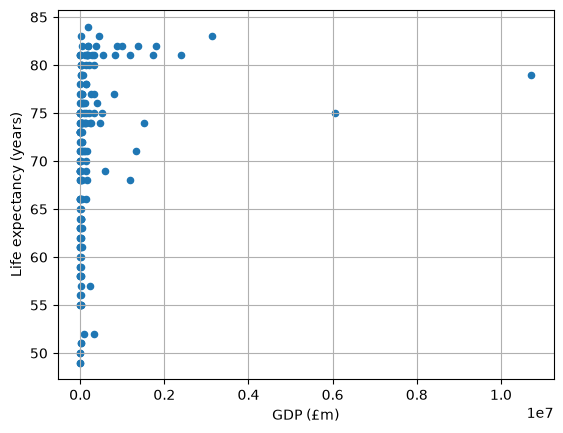

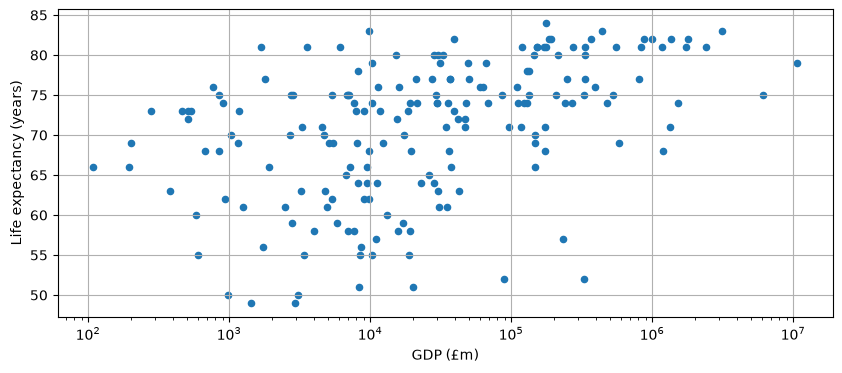

In [70]:
%matplotlib inline
gdpVsLifeClean.plot(x=GDP, y=LIFE, kind='scatter', grid=True)
gdpVsLifeClean.plot(x=GDP, y=LIFE, kind='scatter', grid=True, logx=True, figsize=(10, 4))

<Axes: xlabel='Life expectancy (years)', ylabel='GDP (£m)'>

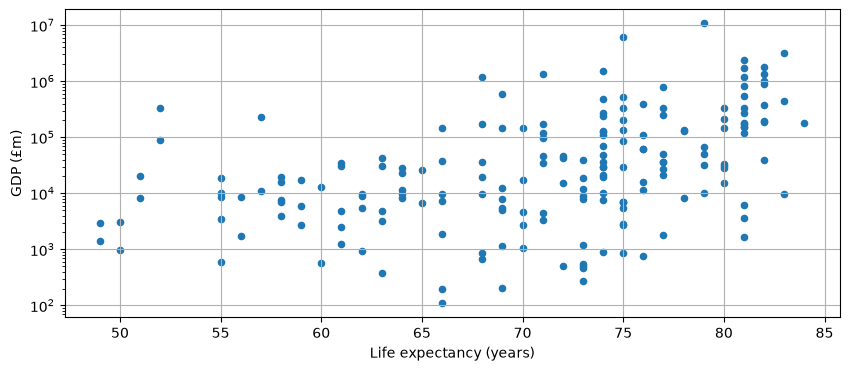

In [71]:
gdpVsLifeClean.plot(x=LIFE, y=GDP, kind='scatter', grid=True, logy=True, figsize=(10, 4))

Text(0, 0.5, 'Population')

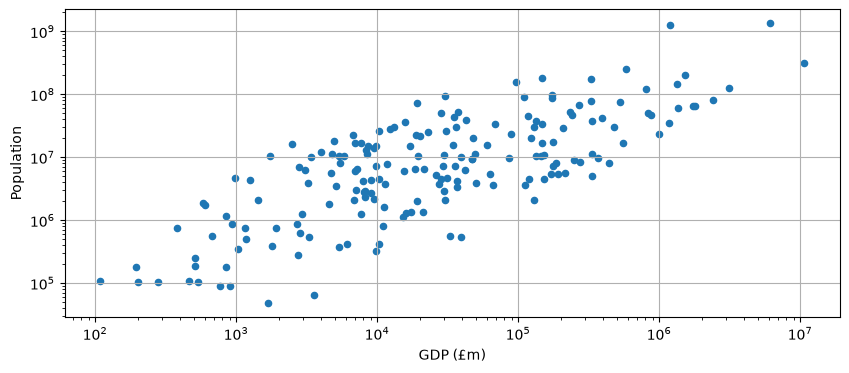

In [73]:
gdpLifePopAll.plot(x=GDP, y=POP_INDICATOR, kind='scatter', grid=True, logx=True, logy=True, figsize=(10, 4))
plt.ylabel('Population')

### Provide `2-Transforming & Combining Data/2.ipynb` Assignment Solutions below (Execute them)

In [136]:
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

GDP_INDICATOR = 'NY.GDP.MKTP.CD'
gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")

LIFE_INDICATOR = 'SP.DYN.LE00.IN'
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")

In [137]:
COUNTRY = 'country'

In [111]:
top10_gdp = gdpLifePopAll.sort_values(GDP, ascending=False).head(10)
top10_life = gdpLifePopAll.sort_values(LIFE_INDICATOR, ascending=False).head(10)

display(top10_gdp[[COUNTRY, GDP, LIFE]])
display(top10_life[[COUNTRY, GDP, LIFE]])

both = pd.merge(top10_gdp[[COUNTRY]], top10_life[[COUNTRY]], on=COUNTRY, how='inner')
print(len(both), 'countries appear in both lists')
both

,country,GDP (£m),Life expectancy (years)
177,United States,10715999,79
35,China,6065182,75
83,Japan,3143957,83
62,Germany,2393529,81
58,France,1795953,82
176,United Kingdom,1733354,81
23,Brazil,1528714,74
81,Italy,1363486,82
138,Russian Federation,1328647,71
75,India,1189826,68


,country,GDP (£m),Life expectancy (years)
72,"Hong Kong SAR, China",176220,84
83,Japan,3143957,83
74,Iceland,9827,83
162,Switzerland,437713,83
154,Spain,875057,82
147,Singapore,193157,82
81,Italy,1363486,82
7,Australia,999478,82
80,Israel,186870,82
58,France,1795953,82


3 countries appear in both lists


,country
0,Japan
1,France
2,Italy


In [112]:
low_life = gdpVsLifeClean[gdpVsLifeClean[LIFE] < 60].sort_values(GDP, ascending=False)
display(low_life.head(5))

top2 = low_life.head(2)
print('The two countries with the highest GDP and a life expectancy below 60 are:',
      ' and '.join(top2[COUNTRY]))

,country,GDP (£m),Life expectancy (years)
124,Nigeria,329100,52
152,South Africa,234056,57
3,Angola,88420,52
41,Cote d'Ivoire,19998,51
38,"Congo, Dem. Rep.",19182,58


The two countries with the highest GDP and a life expectancy below 60 are: Nigeria and South Africa


In [113]:
GDP_PC = 'GDP per capita (£)'

gdpLifePopAll[GDP_PC] = (gdpLifePopAll[GDP_INDICATOR] / gdpLifePopAll[POP_INDICATOR]).apply(usdToGBP).round()

(correlation, pValue) = spearmanr(gdpLifePopAll[GDP_PC], gdpLifePopAll[LIFE])
print('GDP per capita vs life expectancy:', correlation)
print('Total GDP vs life expectancy:     ', spearmanr(gdpLifePopAll[GDP], gdpLifePopAll[LIFE])[0])
print('Statistically significant' if pValue < 0.05 else 'Not statistically significant')

GDP per capita vs life expectancy: 0.8502515138873855
Total GDP vs life expectancy:      0.5010232389671027
Statistically significant


,country,GDP per capita (£),Life expectancy (years)
103,Malawi,153.0,61
27,Burundi,166.0,56
32,Central African Republic,209.0,50
38,"Congo, Dem. Rep.",264.0,58
123,Niger,267.0,61
96,Liberia,290.0,61
102,Madagascar,296.0,65
60,"Gambia, The",309.0,60
54,Ethiopia,322.0,63
151,Somalia,333.0,55


,country,GDP per capita (£),Life expectancy (years)
95,Lesotho,681.0,49
160,Swaziland,2331.0,49
32,Central African Republic,209.0,50
146,Sierra Leone,500.0,50
33,Chad,630.0,51
41,Cote d'Ivoire,925.0,51
3,Angola,3771.0,52
124,Nigeria,1904.0,52
30,Cameroon,851.0,55
153,South Sudan,740.0,55


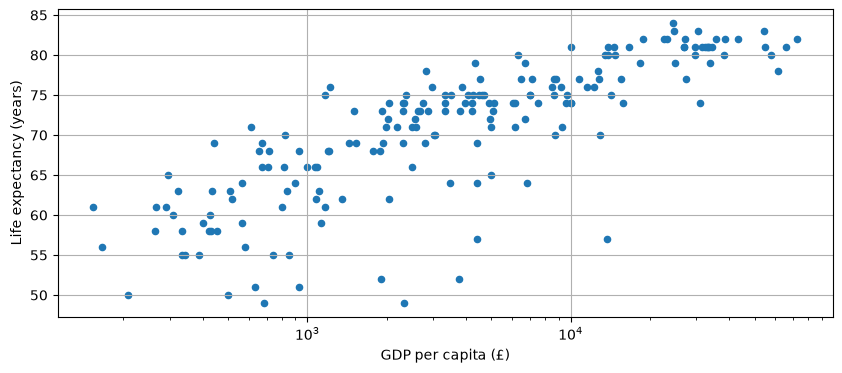

In [114]:
gdpLifePopAll.plot(x=GDP_PC, y=LIFE, kind='scatter', grid=True, logx=True, figsize=(10, 4))

cols = [COUNTRY, GDP_PC, LIFE]
display(gdpLifePopAll.sort_values(GDP_PC).head(10)[cols])
display(gdpLifePopAll.sort_values(LIFE).head(10)[cols])

In [115]:
outliers = gdpLifePopAll[(gdpLifePopAll[LIFE] < 60) & (gdpLifePopAll[GDP_PC] > 2000)]
outliers.sort_values(GDP_PC, ascending=False)[[COUNTRY, GDP_PC, LIFE]]

,country,GDP per capita (£),Life expectancy (years)
52,Equatorial Guinea,13739.0,57
152,South Africa,4403.0,57
3,Angola,3771.0,52
160,Swaziland,2331.0,49


**Why is life expectancy lower in these countries than in countries with a similar GDP?**

Total GDP describes the size of an economy. It says nothing about how many people share that income or what it is spent on. Nigeria and South Africa both have large economies, so they sit on the right of the plot, but both also have large populations. In my GDP per capita results, Nigeria's GDP per person is only about £1,904, because its total GDP is shared among more than 170 million people.

Income also does not translate directly into health. In my GDP per capita table, Malawi has the lowest GDP per person in the dataset (£153) and a life expectancy of 61 years, while Nigeria has more than ten times that income and a life expectancy of only 52. This suggests that other factors matter more than the amount of money in an economy.

In Nigeria, a large part of national income comes from oil exports, and many people live in poverty with limited access to clean water and basic healthcare. Malaria and HIV remain widespread, and child and maternal mortality are high, which pulls the national average down.

In South Africa, the HIV/AIDS epidemic is the main factor. It has been one of the largest in the world, and life expectancy fell sharply in the 1990s and 2000s as a result. Tuberculosis also remains common, and income inequality is among the highest in the world, so the wealth in the economy reaches many people unevenly.

**Question 4: Analysis using GDP per capita**

The Spearman correlation between GDP per capita and life expectancy is [value], compared with [value] for total GDP, and it is statistically significant. The scatterplot shows a much tighter upward pattern than the plot with total GDP, so GDP per person describes the link with life expectancy better than the size of the economy does. The countries with the lowest GDP per capita, such as Malawi, Burundi and the Central African Republic, have life expectancies between 50 and 61 years, while the countries with the lowest life expectancy, such as Lesotho, Swaziland and Sierra Leone, are also low-income. A few countries, including [names from the optional outlier cell], have middling incomes but low life expectancy.

In [144]:
import requests

COUNTRY = 'country'
PPP_INDICATOR = 'NY.GDP.PCAP.PP.CD'

def worldBank(indicator, year=2013):
    url = f"https://api.worldbank.org/v2/country/all/indicator/{indicator}"
    response = requests.get(url, params={'date': year, 'format': 'json', 'per_page': 400}, timeout=60)
    data = response.json()
    rows = [(r['country']['value'], r['value']) for r in data[1]]
    return pd.DataFrame(rows, columns=[COUNTRY, indicator]).dropna()

ppp = worldBank(PPP_INDICATOR)
print(ppp.shape)
ppp.head()

(248, 2)


,country,NY.GDP.PCAP.PP.CD
0,Africa Eastern and Southern,3373.428766
1,Africa Western and Central,4867.130763
2,Arab World,16054.040416
3,Caribbean small states,20901.494764
4,Central Europe and the Baltics,23869.112331


In [148]:
LIFE = 'Life expectancy (years)'

renames = {
    'Eswatini': 'Swaziland',
    "Côte d'Ivoire": "Cote d'Ivoire",
    'Türkiye': 'Turkey',
    'Czechia': 'Czech Republic',
    'North Macedonia': 'Macedonia, FYR',
    'Cabo Verde': 'Cape Verde',
}
ppp[COUNTRY] = ppp[COUNTRY].replace(renames)

pppVsLife = pd.merge(ppp, lifeClean, on=COUNTRY, how='inner')   # the inner join also drops the regional groups
pppVsLife[LIFE] = pppVsLife[LIFE_INDICATOR].apply(round)

missing = sorted(set(lifeClean[COUNTRY]) - set(pppVsLife[COUNTRY]))
print('Countries after the merge:', len(pppVsLife), 'of', len(lifeClean))
print('In the life expectancy table but with no PPP match:', missing)

(correlation, pValue) = spearmanr(pppVsLife[PPP_INDICATOR], pppVsLife[LIFE])
print('GDP per capita (PPP) vs life expectancy:', correlation)
print('Statistically significant' if pValue < 0.05 else 'Not statistically significant')

Countries after the merge: 181 of 198
In the life expectancy table but with no PPP match: ['Cabo Verde', 'Channel Islands', 'Cuba', 'Eritrea', 'Faeroe Islands', 'French Polynesia', 'Guam', 'Korea, Dem. Rep.', 'Liechtenstein', 'New Caledonia', 'Puerto Rico', 'Somalia', 'St. Martin (French part)', 'Syrian Arab Republic', 'Turkey', 'Venezuela, RB', 'Vietnam']
GDP per capita (PPP) vs life expectancy: 0.8521915878957582
Statistically significant


,country,NY.GDP.PCAP.PP.CD,Life expectancy (years)
28,Burundi,687.370968,56
32,Central African Republic,709.853481,50
38,"Congo, Dem. Rep.",760.649880,58
114,Mozambique,1113.752528,55
121,Niger,1137.769041,61
54,Ethiopia,1252.868964,63
95,Liberia,1360.129104,61
67,Guinea-Bissau,1415.825119,55
100,Madagascar,1473.403981,65
137,Rwanda,1491.803708,63


,country,NY.GDP.PCAP.PP.CD,Life expectancy (years)
94,Lesotho,2538.263103,49
53,Swaziland,8231.151398,49
32,Central African Republic,709.853481,50
144,Sierra Leone,2700.738078,50
33,Chad,2110.247051,51
41,Cote d'Ivoire,3619.017909,51
3,Angola,8504.095321,52
122,Nigeria,7004.131195,52
67,Guinea-Bissau,1415.825119,55
30,Cameroon,3238.868298,55


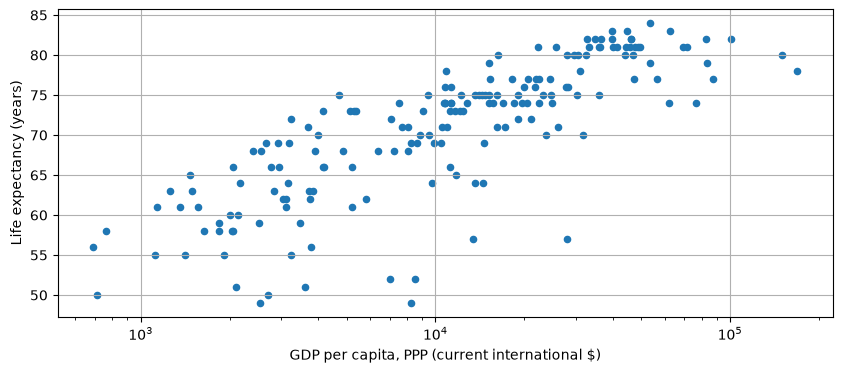

In [142]:
pppVsLife.plot(x=PPP_INDICATOR, y=LIFE, kind='scatter', grid=True, logx=True, figsize=(10, 4))
plt.xlabel('GDP per capita, PPP (current international $)')

cols = [COUNTRY, PPP_INDICATOR, LIFE]
display(pppVsLife.sort_values(PPP_INDICATOR).head(10)[cols])
display(pppVsLife.sort_values(LIFE).head(10)[cols])

**Analysis using GDP per capita adjusted for purchasing power (NY.GDP.PCAP.PP.CD)**

The Spearman correlation between GDP per capita (PPP) and life expectancy is [value], compared with [value] for GDP per capita in pounds and [value] for total GDP. [One or two sentences on whether it is stronger and what the scatterplot shows.] [Mention how many countries were matched, and that a few could not be matched because the two sources spell some names differently.]

## Project B: GDP and life expectancy

Richer countries can afford to invest more on healthcare, on work and road safety, and other measures that reduce mortality. On the other hand, richer countries may have less healthy lifestyles. Is there any relation between the wealth of a country and the life expectancy of its inhabitants?

The following analysis checks whether there is any correlation between the total gross domestic product (GDP) of a country in 2013 and the life expectancy of people born in that country in 2013.

## Getting the data

Two datasets of the World Bank are considered. One dataset, available at <http://data.worldbank.org/indicator/NY.GDP.MKTP.CD>, lists the GDP of the world's countries in current US dollars, for various years. The use of a common currency allows us to compare GDP values across countries. The other dataset, available at <http://data.worldbank.org/indicator/SP.DYN.LE00.IN>, lists the life expectancy of the world's countries. The datasets were downloaded as CSV files in March 2016.

In [74]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import pandas as pd

# Load Data from cohort database (schema week08). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

YEAR = 2013
GDP_INDICATOR = 'NY.GDP.MKTP.CD'
gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")

LIFE_INDICATOR = 'SP.DYN.LE00.IN'
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")
lifeReset.head()


,country,year,SP.DYN.LE00.IN
0,Arab World,2013,70.631305
1,Caribbean small states,2013,71.901964
2,Central Europe and the Baltics,2013,76.127583
3,East Asia & Pacific (all income levels),2013,74.604619
4,East Asia & Pacific (developing only),2013,73.657617


## Cleaning the data

Inspecting the data with `head()` and `tail()` shows that:

1. the first 34 rows are aggregated data, for the Arab World, the Caribbean small states, and other country groups used by the World Bank;
- GDP and life expectancy values are missing for some countries.

The data is therefore cleaned by:
1. removing the first 34 rows;
- removing rows with unavailable values.

In [75]:
gdpCountries = gdpReset[34:].dropna()
lifeCountries = lifeReset[34:].dropna()

## Transforming the data

The World Bank reports GDP in US dollars and cents. To make the data easier to read, the GDP is converted to millions of British pounds (the author's local currency) with the following auxiliary functions, using the average 2013 dollar-to-pound conversion rate provided by <http://www.ukforex.co.uk/forex-tools/historical-rate-tools/yearly-average-rates>. 

In [76]:
def roundToMillions (value):
    return round(value / 1000000)

def usdToGBP (usd):
    return usd / 1.564768

GDP = 'GDP (£m)'
gdpCountries[GDP] = gdpCountries[GDP_INDICATOR].apply(usdToGBP).apply(roundToMillions)
gdpCountries.head()

,country,year,NY.GDP.MKTP.CD,GDP (£m)
34,Afghanistan,2013,2.045894e+10,13075
35,Albania,2013,1.278103e+10,8168
36,Algeria,2013,2.097035e+11,134016
38,Andorra,2013,3.249101e+09,2076
39,Angola,2013,1.383568e+11,88420


The unnecessary columns can be dropped.

In [77]:
COUNTRY = 'country'
headings = [COUNTRY, GDP]
gdpClean = gdpCountries[headings]
gdpClean.head()

,country,GDP (£m)
34,Afghanistan,13075
35,Albania,8168
36,Algeria,134016
38,Andorra,2076
39,Angola,88420


The World Bank reports the life expectancy with several decimal places. After rounding, the original column is discarded.

In [5]:
LIFE = 'Life expectancy (years)'
lifeCountries[LIFE] = lifeCountries[LIFE_INDICATOR].apply(round)
headings = [COUNTRY, LIFE]
lifeClean = lifeCountries[headings]
lifeClean.head()

,country,Life expectancy (years)
34,Afghanistan,60
35,Albania,78
36,Algeria,75
39,Angola,52
40,Antigua and Barbuda,76


## Combining the data

The tables are combined through an inner join on the common 'country' column. 

In [132]:
gdpVsLife = pd.merge(gdpClean, lifeClean, on=COUNTRY, how='inner')
gdpVsLife.head()

,country,GDP (£m),SP.DYN.LE00.IN
0,Afghanistan,13075,60.028268
1,Albania,8168,77.537244
2,Algeria,134016,74.568951
3,Angola,88420,51.866171
4,Antigua and Barbuda,767,75.778659


## Calculating the correlation

To measure if the life expectancy and the GDP grow together, the Spearman rank correlation coefficient is used. It is a number from -1 (perfect inverse rank correlation: if one indicator increases, the other decreases) to 1 (perfect direct rank correlation: if one indicator increases, so does the other), with 0 meaning there is no rank correlation. A perfect correlation doesn't imply any cause-effect relation between the two indicators. A p-value below 0.05 means the correlation is statistically significant.

In [78]:
from scipy.stats import spearmanr

gdpColumn = gdpVsLife[GDP]
lifeColumn = gdpVsLife[LIFE]
(correlation, pValue) = spearmanr(gdpColumn, lifeColumn)
print('The correlation is', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

The correlation is -0.5
It is not statistically significant.


The value shows a direct correlation, i.e. richer countries tend to have longer life expectancy, but it is not very strong.

## Showing the data

Measures of correlation can be misleading, so it is best to see the overall picture with a scatterplot. The GDP axis uses a logarithmic scale to better display the vast range of GDP values, from a few million to several billion (million of million) pounds.

<Axes: xlabel='GDP (£m)', ylabel='Life expectancy (years)'>

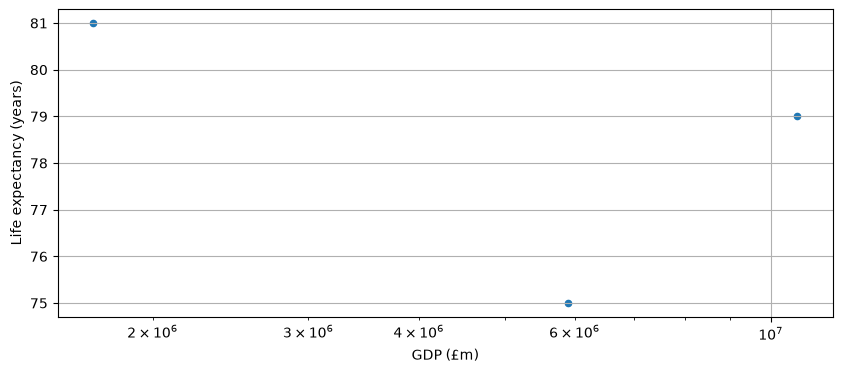

In [79]:
%matplotlib inline
gdpVsLife.plot(x=GDP, y=LIFE, kind='scatter', grid=True, logx=True, figsize=(10, 4))

The plot shows there is no clear correlation: there are rich countries with low life expectancy, poor countries with high expectancy, and countries with around 10 thousand (10<sup>4</sup>) million pounds GDP have almost the full range of values, from below 50 to over 80 years. Towards the lower and higher end of GDP, the variation diminishes. Above 40 thousand million pounds of GDP (3rd tick mark to the right of 10<sup>4</sup>), most countries have an expectancy of 70 years or more, whilst below that threshold most countries' life expectancy is below 70 years. 

Comparing the 10 poorest countries and the 10 countries with the lowest life expectancy shows that total GDP is a rather crude measure. The population size should be taken into account for a more precise definiton of what 'poor' and 'rich' means. Furthermore, looking at the countries below, droughts and internal conflicts may also play a role in life expectancy. 

In [80]:
# the 10 countries with lowest GDP
gdpVsLife.sort_values(GDP).head(10)

,Country name,GDP (£m),Life expectancy (years)
0,United Kingdom,1711727,81
2,China,5905202,75
1,United States,10716029,79


In [10]:
# the 10 countries with lowest life expectancy
gdpVsLife.sort_values(LIFE).head(10)

,country,GDP (£m),Life expectancy (years)
95,Lesotho,1418,49
160,Swaziland,2916,49
32,Central African Republic,983,50
146,Sierra Leone,3092,50
33,Chad,8276,51
41,Cote d'Ivoire,19998,51
3,Angola,88420,52
124,Nigeria,329100,52
30,Cameroon,18896,55
153,South Sudan,8473,55


## Conclusions

To sum up, there is no strong correlation between a country's wealth and the life expectancy of its inhabitants: there is often a wide variation of life expectancy for countries with similar GDP, countries with the lowest life expectancy are not the poorest countries, and countries with the highest expectancy are not the richest countries. Nevertheless there is some relationship, because the vast majority of countries with a life expectancy below 70 years is on the left half of the scatterplot.

Using the [NY.GDP.PCAP.PP.CD](http://data.worldbank.org/indicator/NY.GDP.PCAP.PP.CD) indicator, GDP per capita in current 'international dollars', would make for a better like-for-like comparison between countries, because it would take population and purchasing power into account. Using more specific data, like expediture on health, could also lead to a better analysis.

### Assessment - NOW IS YOUR TURN

**Create your own project**
Create a completely new project and choose another two of the
hundreds of World Bank indicators and see if there is any correlation between them. If
there is a choice of similar indicators, choose one that leads to meaningful
comparisons between countries.

Look at the results you obtained and take a few moments to assess how they differ.


## GOOD LUCK!

224 countries
Spearman: 0.9230621806378425 | p-value: 4.4411221750634154e-94


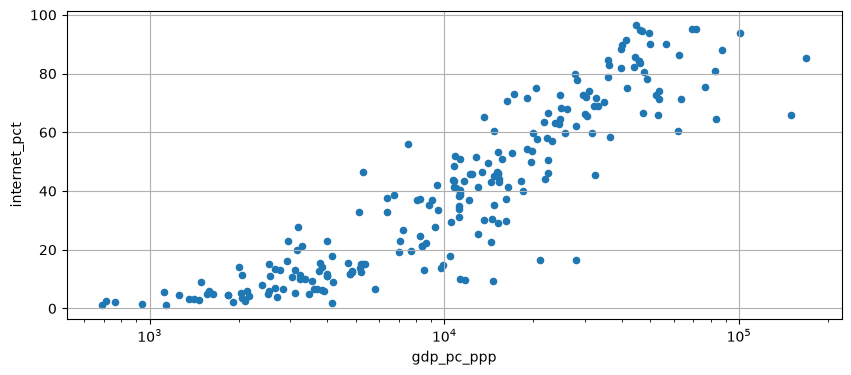

In [147]:
X_IND = 'IT.NET.USER.ZS'
Y_IND = 'NY.GDP.PCAP.PP.CD'

x = worldBank(X_IND, year=2013).rename(columns={X_IND: 'internet_pct'})
y = worldBank(Y_IND, year=2013).rename(columns={Y_IND: 'gdp_pc_ppp'})

df = pd.merge(x, y, on=COUNTRY, how='inner').dropna()
print(len(df), "countries")

corr, p = spearmanr(df['internet_pct'], df['gdp_pc_ppp'])
print("Spearman:", corr, "| p-value:", p)

df.plot(x='gdp_pc_ppp', y='internet_pct', kind='scatter', logx=True, grid=True, figsize=(10, 4))
plt.show()

<!-- practice:start -->
---
## 🔁 SQL Practice

This week you cleaned messy weather data and combined World Bank tables in pandas. Now do the same jobs **in SQL**, straight from the raw tables: real analysts clean and combine data in the database before it ever reaches pandas.

**How it works**
1. Run the **practice setup** cell first (and again after restarting the kernel). It connects with your **read-only** account.
2. **SQL tasks:** write your query between the triple quotes and run the cell. `p.sql(...)` shows your result and
   says ✅ or ❌, and whether the **shape** (rows × columns) is right. Match the column order, sort order and rounding
   asked for (column *names* aren't checked).
3. Run `p.score()` at the end to see your practice score.

Refresh your memory with `Week-6 (Numpy & Pandas-1)/4-Intermediate SQL/Intermediate SQL.ipynb`.

In [122]:
# --- practice setup: run this cell first (don't edit it) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.practice import Practice, q

EXPECTED = {
 "s01": [
  [
   1,
   1
  ],
  "1ba5edf59854386be920ac9fd3e4a2af3bb6369bf2a1aef78dcdf908c96d70a9"
 ],
 "s02": [
  [
   5,
   3
  ],
  "19042d389224a7f56403ad9636ed581989f6639acadf45b15461f55cd6258da7"
 ],
 "s03": [
  [
   10,
   3
  ],
  "e3e296058facb3595b46ac98fb75d445a82240fc775f3188d029eabc5a362ddb"
 ],
 "s04": [
  [
   1,
   1
  ],
  "ba4a24ee999caa9e01607eb78856b7212bcce521b0f6fd42d8aa90541c10382d"
 ],
 "s05": [
  [
   1,
   2
  ],
  "8153d8bbbc1b43b88ce7e4ea0c99a4ac07f4b19e0f62a9a1e04df3271f2ad3df"
 ]
}   # fingerprints only: the answers are not stored here
TITLES = {
 "s01": "Cleaning a messy column",
 "s02": "Dates: a date range",
 "s03": "Combining tables (JOIN)",
 "s04": "What gets lost in a join?",
 "s05": "Window: the driest summer week"
}
p = Practice(EXPECTED, TITLES)
print(f"Practice ready: {len(TITLES)} tasks. Connected as:", q("SELECT CURRENT_USER AS u").u[0])

Practice ready: 5 tasks. Connected as: intern_readonly


### SQL Task 1 · Cleaning a messy column

`week07.london_2014` is the **raw** export: the last column is literally named `WindDirDegrees<br />` and every
value ends in `<br />` (e.g. `'186<br />'`). Clean it **in SQL**: remove the `<br />`, convert to an integer, and
count the days when the wind direction was **greater than 350 degrees**.

**Return:** one row, one column (`days_over_350`).
💡 `REPLACE(...)`, `TRY_CAST(... AS int)`, and bracket-quote the odd column name: `[WindDirDegrees<br />]`.

In [123]:
SQL_01 = """
SELECT COUNT(*) AS days_over_350
FROM week07.london_2014
WHERE TRY_CAST(REPLACE([WindDirDegrees<br />], '<br />', '') AS int) > 350
"""
p.sql("s01", SQL_01)

,days_over_350
0,5


✅ s01: correct!


,days_over_350
0,5


### SQL Task 2 · Dates: a date range

`GMT` is stored as **text** like `'2014-1-1'`. Convert it to a real date and return London's weather for
**8–12 December 2014** (inclusive).

**Return:** `day` (a date), `Max TemperatureC`, `Min TemperatureC`, sorted by `day`.
💡 `TRY_CONVERT(date, GMT)` and `BETWEEN`.

In [124]:
SQL_02 = """
SELECT TRY_CONVERT(date, GMT) AS day,
       [Max TemperatureC],
       [Min TemperatureC]
FROM week07.london_2014
WHERE TRY_CONVERT(date, GMT) BETWEEN '2014-12-08' AND '2014-12-12'
ORDER BY day
"""
p.sql("s02", SQL_02)

,day,Max TemperatureC,Min TemperatureC
0,2014-12-08,7,1
1,2014-12-09,12,-1
2,2014-12-10,9,6
3,2014-12-11,10,5
4,2014-12-12,9,2


✅ s02: correct!


,day,Max TemperatureC,Min TemperatureC
0,2014-12-08,7,1
1,2014-12-09,12,-1
2,2014-12-10,9,6
3,2014-12-11,10,5
4,2014-12-12,9,2


### SQL Task 3 · Combining tables (JOIN)

Join `week08.wb_gdp_2013` and `week08.wb_le_2013` on `country`. Among entries with GDP **below 10 billion USD**
and a known life expectancy, return the **10 with the highest life expectancy**.

**Return:** `country`, `gdp_bn_usd` (GDP in billions, **rounded to 2 dp**), `life_expectancy` (**rounded to 1 dp**),
sorted by life expectancy (highest first), then `country` (A→Z) for ties.

In [125]:
SQL_03 = """
SELECT TOP 10 g.country,
       ROUND(g.[NY.GDP.MKTP.CD] / 1e9, 2) AS gdp_bn_usd,
       ROUND(l.[SP.DYN.LE00.IN], 1) AS life_expectancy
FROM week08.wb_gdp_2013 g
JOIN week08.wb_le_2013 l ON g.country = l.country
WHERE g.[NY.GDP.MKTP.CD] < 1e10
  AND l.[SP.DYN.LE00.IN] IS NOT NULL
ORDER BY life_expectancy DESC, g.country
"""
p.sql("s03", SQL_03)

,country,gdp_bn_usd,life_expectancy
0,Faeroe Islands,2.61,81.3
1,Malta,9.64,80.7
2,Bermuda,5.57,80.6
3,Maldives,2.79,76.6
4,Antigua and Barbuda,1.20,75.8
5,Barbados,4.28,75.3
6,"Bahamas, The",8.43,75.1
7,St. Lucia,1.33,74.9
8,Montenegro,4.46,74.8
9,Seychelles,1.41,74.2


✅ s03: correct!


,country,gdp_bn_usd,life_expectancy
0,Faeroe Islands,2.61,81.3
1,Malta,9.64,80.7
2,Bermuda,5.57,80.6
3,Maldives,2.79,76.6
4,Antigua and Barbuda,1.20,75.8
5,Barbados,4.28,75.3
6,"Bahamas, The",8.43,75.1
7,St. Lucia,1.33,74.9
8,Montenegro,4.46,74.8
9,Seychelles,1.41,74.2


### SQL Task 4 · What gets lost in a join?

In the lesson, `dropna()` removed rows before the merge. Count what would be lost: how many rows of
`week08.wb_gdp_2013` have **no usable match**, meaning either GDP is NULL, or the life-expectancy value for that
country is NULL (or missing)?

**Return:** one row, one column (`rows_lost`).
💡 `LEFT JOIN` and test for NULLs on both sides.

In [127]:
SQL_04 = """
SELECT COUNT(*) AS rows_lost
FROM week08.wb_gdp_2013 g
LEFT JOIN week08.wb_le_2013 l ON g.country = l.country
WHERE g.[NY.GDP.MKTP.CD] IS NULL
   OR l.[SP.DYN.LE00.IN] IS NULL
"""
p.sql("s04", SQL_04)

,rows_lost
0,29


✅ s04: correct!


,rows_lost
0,29


### SQL Task 5 · Window: the driest summer week

For the **Holiday weather** project: using London's **summer** (June, July, August 2014), find the **7-day
period with the least total rain**. A period is identified by its **start date** (that day + the next 6 days,
all inside the summer). If several periods tie, take the earliest.

**Return:** one row: `start_day` (a date), `rain_mm_7d` (**rounded to 2 dp**).
💡 `SUM(Precipitationmm) OVER (ORDER BY day ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING)` in a CTE, and only keep
start days whose window has a full 7 days.

In [128]:
SQL_05 = """
WITH d AS (
    SELECT TRY_CONVERT(date, GMT) AS day,
           TRY_CAST(Precipitationmm AS float) AS rain
    FROM week07.london_2014
    WHERE MONTH(TRY_CONVERT(date, GMT)) IN (6, 7, 8)
),
w AS (
    SELECT day,
           SUM(rain) OVER (ORDER BY day ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING) AS rain_7d,
           COUNT(*) OVER (ORDER BY day ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING) AS n
    FROM d
)
SELECT TOP 1 day AS start_day, ROUND(rain_7d, 2) AS rain_mm_7d
FROM w
WHERE n = 7
ORDER BY rain_7d, day
"""
p.sql("s05", SQL_05)

,start_day,rain_mm_7d
0,2014-06-19,0.0


✅ s05: correct!


,start_day,rain_mm_7d
0,2014-06-19,0.0


### Practice score
Run this when you're done.

In [129]:
p.score()

Task Type                          Topic Result
 s01  SQL        Cleaning a messy column      ✅
 s02  SQL            Dates: a date range      ✅
 s03  SQL        Combining tables (JOIN)      ✅
 s04  SQL      What gets lost in a join?      ✅
 s05  SQL Window: the driest summer week      ✅
SQL score: 5 / 5


,Task,Type,Topic,Result
0,s01,SQL,Cleaning a messy column,✅
1,s02,SQL,Dates: a date range,✅
2,s03,SQL,Combining tables (JOIN),✅
3,s04,SQL,What gets lost in a join?,✅
4,s05,SQL,Window: the driest summer week,✅


<!-- practice:end -->

---
## 📰 Article Link

Write a **detailed article** about this week's work. It should cover:

- **What you learnt:** the key concepts, tools and techniques from this week.
- **What you solved:** the tasks and projects you worked on, and how you approached them.
- **Challenges you faced:** what was hard, confusing or didn't work at first.
- **How you overcame them:** what you tried, what finally worked, and what you'd do differently.
- **Anything else you want to share:** insights, results, visuals, or advice for others learning this.

Publish it, then paste the article's **URL** in the empty cell below (double-click the cell to edit it).

https://tinkerwkoko.medium.com/from-messy-data-to-meaningful-results-my-dataraflow-week-7-050ec76af1de